# Nyumbani ML Engine: Random Forest Base Model
**ICS 3202 · Semester Project · Deliverable 2 (CAT 2) · Group D**

| Member | Admission no. | Presents | What I actually did *(each member fills in honestly)* |
|---|---|---|---|
| Atogo Carl | 191245 | Section A (Steps 1-3) | |
| Bill Kevin | 189725 | Section B (Steps 4-6) | |
| Segera Rooney | 189735 | Section C (Steps 7-10) | |

## What this notebook does (in plain words)
A tenant types a problem (*"the kitchen tap is dripping"*). Our model must decide the **service category** (for example plumbing) so the request goes to the right provider. This is a **classification** problem.

**Data:** NYC 311 housing-repair requests (HPD agency), 2025, about 48,000 rows.
**Model:** TF-IDF + Random Forest. TF-IDF turns text into numbers. A Random Forest is many decision trees (flowcharts of yes/no questions) that **vote**; because the trees differ, their mistakes tend to cancel out.

| Step | What we do | Question |
|---|---|---|
| 1 | Get the data | Q2 |
| 2 | Explore the raw data | Q2 |
| 3 | Clean it (with a log) | Q2 |
| 4 | EDA: 5 observations | Q2 |
| 5 | Split into train/test and set a baseline | Q3 |
| 6 | Write a realistic tenant-sentence test | Q3 |
| 7 | Train and tune the Random Forest | Q3 |
| 8 | Evaluate on both tests | Q3 |
| 9 | Compare with other models | Q4 |
| 10 | Limitations and next steps | - |

In [1]:
import os, re, time, warnings, requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
SEED = 42   # fixed seed: everyone gets the same results

# Section A: Data and cleaning

## Step 1: Get the data
We use requests handled by **HPD** (the NYC housing-repairs agency), because they are tenant repair problems like our app's. We take a **full year (2025)** with up to 4,000 requests per month, so every season is represented and no month dominates. We download only the columns we need and save them to a file, so we download once.

In [2]:
URL = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
CACHE = "nyc311_hpd_2025.csv"
COLS = "unique_key,created_date,agency,complaint_type,descriptor,descriptor_2,location_type,borough"

def load_data():
    if os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    parts = []
    for m in range(1, 13):
        start = pd.Timestamp(2025, m, 1)
        end = start + pd.offsets.MonthBegin(1) - pd.Timedelta(seconds=1)
        q = {"$select": COLS, "$order": "unique_key", "$limit": 4000,
             "$where": f"agency='HPD' AND created_date between '{start:%Y-%m-%dT%H:%M:%S}' and '{end:%Y-%m-%dT%H:%M:%S}'"}
        r = requests.get(URL, params=q, timeout=120); r.raise_for_status()
        parts.append(pd.DataFrame(r.json())); time.sleep(0.5)
    out = pd.concat(parts, ignore_index=True); out.to_csv(CACHE, index=False)
    return out

raw = load_data()
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

Raw data: 48,000 rows x 8 columns


## Step 2: Explore the raw data
Before cleaning, we look at what is wrong with the data, so every cleaning step answers something we saw: data types, missing values, duplicates, how big each category is, and what the text looks like.

In [3]:
raw.info()
summary = (raw.isnull().mean() * 100).round(1).rename("% missing").to_frame()
summary["n_unique"] = raw.nunique()
display(summary)
print("Duplicate unique_key values:", raw["unique_key"].duplicated().sum())
print("Categories as written:", raw["complaint_type"].nunique(),
      "| after upper-casing and trimming:", raw["complaint_type"].str.upper().str.strip().nunique())
print("\n", raw["complaint_type"].value_counts())
print("\n", raw["descriptor"].value_counts().head(8))
raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   unique_key      48000 non-null  int64
 1   created_date    48000 non-null  str  
 2   agency          48000 non-null  str  
 3   complaint_type  48000 non-null  str  
 4   descriptor      48000 non-null  str  
 5   descriptor_2    45527 non-null  str  
 6   location_type   48000 non-null  str  
 7   borough         48000 non-null  str  
dtypes: int64(1), str(7)
memory usage: 2.9 MB


,% missing,n_unique
unique_key,0.0,48000
created_date,0.0,31349
agency,0.0,1
complaint_type,0.0,13
descriptor,0.0,56
descriptor_2,5.2,124
location_type,0.0,1
borough,0.0,5


Duplicate unique_key values: 0
Categories as written: 13 | after upper-casing and trimming: 13

 complaint_type
HEAT/HOT WATER          16462
UNSANITARY CONDITION     8210
PLUMBING                 4633
PAINT/PLASTER            4143
DOOR/WINDOW              3183
WATER LEAK               2365
GENERAL                  2293
ELECTRIC                 2196
FLOORING/STAIRS          1984
APPLIANCE                1466
SAFETY                    913
ELEVATOR                  105
OUTSIDE BUILDING           47
Name: count, dtype: int64

 descriptor
ENTIRE BUILDING    10892
APARTMENT ONLY      5570
PESTS               4282
MOLD                2473
WALL                2055
FLOOR               1901
CEILING             1852
DOOR                1802
Name: count, dtype: int64


,unique_key,created_date,agency,complaint_type,descriptor,descriptor_2,location_type,borough
0,63586475,2025-01-01T10:53:30.000,HPD,APPLIANCE,ELECTRIC/GAS RANGE,CONTROL KNOB BROKEN OR MISSING,RESIDENTIAL BUILDING,BRONX
1,63586482,2025-01-01T08:11:11.000,HPD,DOOR/WINDOW,DOOR,NEEDS KEY FOR EXIT,RESIDENTIAL BUILDING,BRONX
2,63586485,2025-01-01T07:01:03.000,HPD,DOOR/WINDOW,DOOR FRAME,FRAME BROKEN,RESIDENTIAL BUILDING,BROOKLYN
3,63586490,2025-01-01T18:43:58.000,HPD,ELECTRIC,LIGHTING,FIXTURE WET OR FLOODED,RESIDENTIAL BUILDING,BRONX
4,63586491,2025-01-01T18:53:50.000,HPD,ELECTRIC,NO LIGHTING,ONE ROOM OR AREA,RESIDENTIAL BUILDING,BRONX


**What we found and what we do**

| Finding | Decision |
|---|---|
| Dates are plain text | Convert to real dates |
| No missing values or duplicates | Still check and log "none found" |
| Elevator (105) and Outside Building (47) have very few rows | Remove categories below a minimum size |
| Heat/Hot Water is about a third of all rows | Use macro-F1 and balanced class weights later |
| The description fields are short menu-like phrases | Join them into one text input |

## Step 3: Clean the data
Each step is recorded in a **cleaning log** (rows left after each step). The model reads **text only**, because that is all a tenant gives the app.

In [4]:
log = []
def step(name, d, note): log.append({"step": name, "rows_left": len(d), "note": note})

def clean_text(s):                          # lower-case, drop punctuation, tidy spaces
    s = re.sub(r"[^a-z0-9 ]", " ", s.lower().replace("/", " "))
    return re.sub(r"\s+", " ", s).strip()

df = raw.copy(); step("0. Raw", df, "as downloaded")

n = len(df); df = df.drop_duplicates("unique_key").copy()
step("1. Remove duplicates", df, f"{n-len(df)} found")

df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
n = len(df); df = df.dropna(subset=["created_date"]).copy()
step("2. Convert dates", df, f"{n-len(df)} unreadable")

for c in ["complaint_type", "descriptor", "descriptor_2", "borough"]:      # same word, same spelling
    df[c] = df[c].fillna("").astype(str).str.upper().str.strip().str.replace(r"\s+", " ", regex=True)
step("3. Standardise text", df, "upper-case, trim spaces")

n = len(df); df = df[(df["complaint_type"] != "") & (df["descriptor"] != "")].copy()
step("4. Drop rows with no category/description", df, f"{n-len(df)} dropped")

df["text"] = (df["descriptor"] + " " + df["descriptor_2"]).map(clean_text)   # what the model reads
n = len(df); df = df[df["text"] != ""].copy()
step("5. Build text input", df, f"descriptor + descriptor_2; {n-len(df)} empty dropped")

MIN_ROWS = 100                              # too few examples to learn or test fairly
counts = df["complaint_type"].value_counts(); tiny = counts[counts < MIN_ROWS]
n = len(df); df = df[~df["complaint_type"].isin(tiny.index)].copy()
step("6. Remove tiny categories", df, f"removed {list(tiny.index)} ({n-len(df)} rows)")

df_clean = df[["text", "complaint_type", "created_date", "borough"]].reset_index(drop=True)
print("Final:", df_clean.shape, "| missing values:", int(df_clean.isnull().sum().sum()),
      "| distinct texts:", df_clean["text"].nunique())
pd.DataFrame(log)

Final: (47953, 4) | missing values: 0 | distinct texts: 152


,step,rows_left,note
0,0. Raw,48000,as downloaded
1,1. Remove duplicates,48000,0 found
2,2. Convert dates,48000,0 unreadable
3,3. Standardise text,48000,"upper-case, trim spaces"
4,4. Drop rows with no category/description,48000,0 dropped
5,5. Build text input,48000,descriptor + descriptor_2; 0 empty dropped
6,6. Remove tiny categories,47953,removed ['OUTSIDE BUILDING'] (47 rows)


# Section B: Exploration, the split and the tenant test

## Step 4: Exploratory data analysis (5 observations)
EDA means asking the data questions. The numbers in each sentence are computed by the code, so they always match the data.

1. IMBALANCE: 'HEAT/HOT WATER' is 34.3% of requests, 'ELEVATOR' only 0.2% (157:1) -> use macro-F1 and balanced weights.
2. MENU-LIKE TEXT: 47,953 requests but only 152 distinct texts -> the text is a fixed menu, not sentences a tenant would type.
3. NO AMBIGUITY: 0 texts appear under more than one category; always guessing each text's usual category is right 100.0% of the time -> a high score here shows the menu was learned.
4. SEASONS: 'HEAT/HOT WATER' goes from 7.8% (month 8) to 68.3% (month 2) of requests.
5. PLACE: 'HEAT/HOT WATER' goes from 17.4% (STATEN ISLAND) to 36.2% (BRONX) across boroughs.


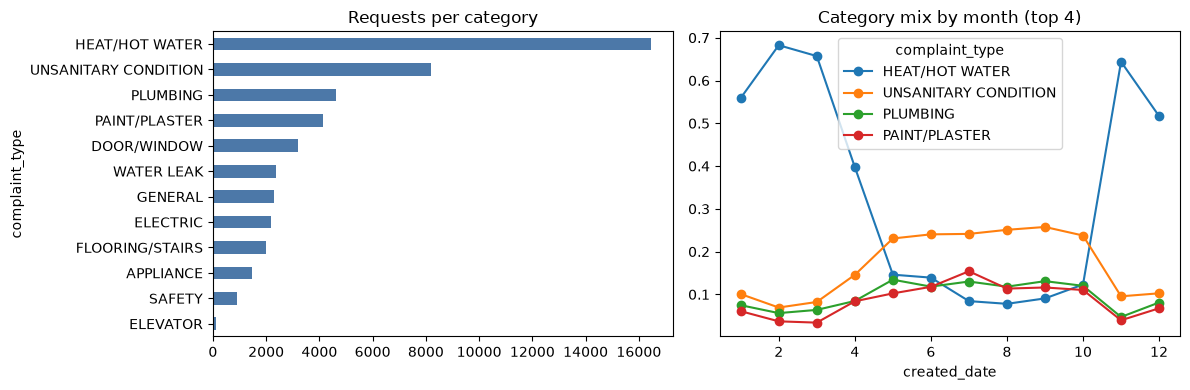

In [5]:
vc = df_clean["complaint_type"].value_counts()
by_text = df_clean.groupby("text")["complaint_type"].agg(["nunique", lambda s: s.value_counts(normalize=True).iloc[0]])
sizes = df_clean.groupby("text").size()
month = pd.crosstab(df_clean["created_date"].dt.month, df_clean["complaint_type"], normalize="index")
big = df_clean["borough"].value_counts(); big = big[big >= 200].index
bor = pd.crosstab(df_clean.loc[df_clean["borough"].isin(big), "borough"], df_clean["complaint_type"], normalize="index")
mc = (month.max() - month.min()).idxmax(); bc = (bor.max() - bor.min()).idxmax()

print(f"1. IMBALANCE: '{vc.index[0]}' is {vc.iloc[0]/len(df_clean):.1%} of requests, '{vc.index[-1]}' only "
      f"{vc.iloc[-1]/len(df_clean):.1%} ({vc.iloc[0]/vc.iloc[-1]:.0f}:1) -> use macro-F1 and balanced weights.")
print(f"2. MENU-LIKE TEXT: {len(df_clean):,} requests but only {df_clean['text'].nunique()} distinct texts "
      f"-> the text is a fixed menu, not sentences a tenant would type.")
print(f"3. NO AMBIGUITY: {(by_text['nunique'] > 1).sum()} texts appear under more than one category; always guessing "
      f"each text's usual category is right {(by_text.iloc[:,1]*sizes).sum()/sizes.sum():.1%} of the time -> a high score here shows the menu was learned.")
print(f"4. SEASONS: '{mc}' goes from {month[mc].min():.1%} (month {month[mc].idxmin()}) to "
      f"{month[mc].max():.1%} (month {month[mc].idxmax()}) of requests.")
print(f"5. PLACE: '{bc}' goes from {bor[bc].min():.1%} ({bor[bc].idxmin()}) to {bor[bc].max():.1%} ({bor[bc].idxmax()}) across boroughs.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
vc.sort_values().plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Requests per category")
month[vc.index[:4]].plot(ax=ax[1], marker="o"); ax[1].set_title("Category mix by month (top 4)")
plt.tight_layout(); plt.show()

| # | Observation | What it changes |
|---|---|---|
| 1 | Categories are very uneven | We use macro-F1 and balanced class weights |
| 2 | Very few distinct texts | Expect high scores; this does not prove the model understands sentences |
| 3 | Every text maps to one category | The data has a 100% ceiling, so it cannot test new wording |
| 4 | Complaints are seasonal | Later, test on future months |
| 5 | The mix differs by place | NYC patterns will not carry over unchanged to a Nairobi estate |

## Step 5: Split the data and set a baseline
We hide 20% of the data (like studying past papers, then sitting a new exam). The split is **stratified**: every category keeps the same share in both parts. The **baseline** always guesses the commonest category; a real model must clearly beat it.

**Accuracy vs macro-F1.** Accuracy counts every request equally, so it favours big categories. **Precision** asks "when the model says Elevator, how often is it right?" and **recall** asks "of all real Elevator requests, how many did it find?". **F1** balances the two, and **macro-F1** averages F1 across categories so a rare category counts as much as a common one.

In [6]:
X, y = df_clean["text"], df_clean["complaint_type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,}   Test: {len(X_test):,}")
print(f"{X_test.isin(set(X_train)).mean():.1%} of test texts also appear in training "
      "-> the normal test mostly checks whether the menu was learned.")
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)
print(f"Baseline (always '{y_train.mode()[0]}'): accuracy {accuracy_score(y_test, base):.3f}, "
      f"macro-F1 {f1_score(y_test, base, average='macro'):.3f}")
y_test.value_counts()

Train: 38,362   Test: 9,591
100.0% of test texts also appear in training -> the normal test mostly checks whether the menu was learned.
Baseline (always 'HEAT/HOT WATER'): accuracy 0.343, macro-F1 0.043


complaint_type
HEAT/HOT WATER          3292
UNSANITARY CONDITION    1642
PLUMBING                 927
PAINT/PLASTER            829
DOOR/WINDOW              637
WATER LEAK               473
GENERAL                  459
ELECTRIC                 439
FLOORING/STAIRS          397
APPLIANCE                293
SAFETY                   182
ELEVATOR                  21
Name: count, dtype: int64

## Step 6: The tenant-sentence test
Because NYC's text is menu-like, the normal test cannot show whether the model handles real wording. We wrote **48 sentences the way a tenant would write, 4 per category, before training**. They are **never used for training or tuning**, and were not edited after seeing results.

In [7]:
tenant = {
 "HEAT/HOT WATER": ["we have had no heating in the flat since Sunday and it is freezing", "the shower only runs cold, there is no hot water at all",
                    "radiators in the whole building are cold again", "hot water goes out every morning in our apartment"],
 "PLUMBING": ["kitchen tap has been dripping since Monday", "the toilet is blocked and will not flush",
              "bathroom sink drains very slowly and smells", "no water is coming out of the taps in my apartment"],
 "WATER LEAK": ["water is leaking through my bedroom ceiling from the flat above", "there is a wet patch spreading on the living room wall",
                "water keeps dripping from the ceiling whenever it rains", "a lot of water is coming down from the bathroom ceiling"],
 "UNSANITARY CONDITION": ["there are cockroaches all over the kitchen cupboards", "mice keep running around the flat at night",
                          "black mold is growing in the corner of the bathroom", "rubbish is piling up outside the building and attracting rats"],
 "PAINT/PLASTER": ["paint is peeling off the bedroom walls", "big cracks have appeared in the living room wall",
                   "pieces of plaster are falling from the ceiling", "the hallway walls need repainting, the paint is flaking everywhere"],
 "DOOR/WINDOW": ["my front door will not lock properly", "the glass in my bedroom window is cracked",
                 "the window frame is rotten and will not close", "the door to my flat has come loose from its hinges"],
 "ELECTRIC": ["the socket in the kitchen sparks when I plug anything in", "lights keep flickering in the whole flat",
              "we have no power in the bedroom", "exposed wires are hanging from the ceiling light"],
 "APPLIANCE": ["the cooker stopped working and will not light", "the fridge in the apartment is not cooling anymore",
               "the oven door is broken and will not stay shut", "one of the stove burners will not turn on"],
 "FLOORING/STAIRS": ["floor tiles are broken and lifting in the kitchen", "one step on the stairs in our block is loose and broken",
                     "the bedroom floorboards are rotten and sagging", "there is a big hole in the hallway floor"],
 "SAFETY": ["the smoke detector in my flat is not working", "the fire escape is blocked and badly rusted",
            "there is no carbon monoxide alarm in our apartment", "the fire exit on our floor is locked shut"],
 "GENERAL": ["the caretaker has not been seen for weeks and nobody answers our requests", "there is no janitor available to fix anything in our building",
             "the superintendent never responds when we call about problems", "no building superintendent has been assigned to our block"],
 "ELEVATOR": ["the lift has been out of order for three days", "the elevator keeps getting stuck between floors",
              "the lift doors will not close properly", "there is no elevator service and I live on the ninth floor"],
}
tenant_df = pd.DataFrame([(s, c) for c, ss in tenant.items() for s in ss], columns=["raw_text", "true"])
tenant_df["text"] = tenant_df["raw_text"].map(clean_text)       # same cleaning as training text
print(len(tenant_df), "sentences;", tenant_df["true"].value_counts().nunique(), "distinct count per category (should be 1)")

# check our labels against what NYC actually puts in each category
for cat in sorted(df_clean["complaint_type"].unique()):
    print(f"{cat:<22}", " | ".join(df_clean.loc[df_clean['complaint_type'] == cat, 'text'].value_counts().head(3).index))

48 sentences; 1 distinct count per category (should be 1)
APPLIANCE              refrigerator broken door seal | electric gas range no gas or electricity | electric gas range pilot light out
DOOR/WINDOW            door broken or missing | door lock broken or missing | window frame loose or defective
ELECTRIC               outlet switch outlet sealed or defective | no lighting one room or area | power outage entire apartment
ELEVATOR               maintenance dirty or unsanitary | maintenance light fixture broken | maintenance glass or mirror broken
FLOORING/STAIRS        floor broken or defective | floor tile broken or missing | floor sagging or sloping
GENERAL                bell buzzer intercom broken or missing | cabinet damaged or missing | cooking gas shut off
HEAT/HOT WATER         entire building no heat | apartment only no heat | entire building no heat and no hot water
PAINT/PLASTER          wall bulging hole cracked | wall chipped peeling flaking | ceiling hole or cracked
PLU

# Section C: Model, results and comparison

## Step 7: Train and tune the Random Forest
A **Pipeline** chains TF-IDF (turns text into numbers, giving more weight to distinctive words like *toilet*) and the Random Forest. Putting both in one pipeline means TF-IDF is learned *inside* each test round, so nothing leaks from the part being tested.

We use **5-fold cross-validation** to choose the settings: split the training data into 5 parts, train on 4, score on the 5th, repeat 5 times, average. This stops us picking settings that suit one lucky split. We try 15 combinations of tree depth (`max_depth`) and smallest group a tree may end on (`min_samples_leaf`), scored by **macro-F1**. The test set and tenant sentences are **not used** here.

Best settings: {'rf__max_depth': None, 'rf__min_samples_leaf': 5} | CV macro-F1: 0.9998


,max_depth,min_samples_leaf,train_F1,cv_F1,cv_std
13,None,5,0.9998,0.9998,0.0003
12,None,1,1.0000,0.9997,0.0003
14,None,20,0.9990,0.9988,0.0009
11,20,20,0.9878,0.9878,0.0031
9,20,1,0.9868,0.9868,0.0027
10,20,5,0.9865,0.9867,0.0028
6,10,1,0.9734,0.9730,0.0026
7,10,5,0.9733,0.9729,0.0026


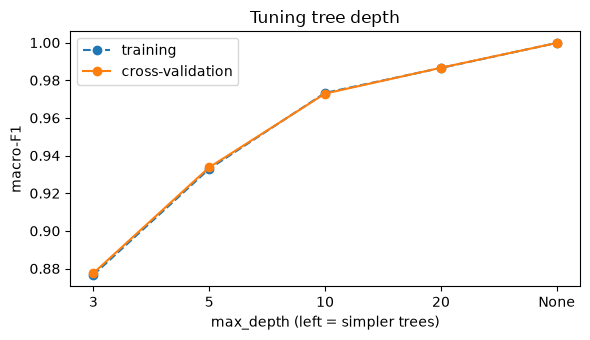

In [8]:
pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                 ("rf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1))])
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
grid = GridSearchCV(pipe, {"rf__max_depth": [3, 5, 10, 20, None], "rf__min_samples_leaf": [1, 5, 20]},
                    cv=cv5, scoring="f1_macro", return_train_score=True).fit(X_train, y_train)
print("Best settings:", grid.best_params_, f"| CV macro-F1: {grid.best_score_:.4f}")

res = pd.DataFrame(grid.cv_results_)[["param_rf__max_depth", "param_rf__min_samples_leaf", "mean_train_score", "mean_test_score", "std_test_score"]]
res.columns = ["max_depth", "min_samples_leaf", "train_F1", "cv_F1", "cv_std"]
display(res.sort_values("cv_F1", ascending=False).round(4).head(8))

d = res[res["min_samples_leaf"] == grid.best_params_["rf__min_samples_leaf"]]
pos = range(len(d)); labels = [str(v) if pd.notna(v) else "None" for v in d["max_depth"]]
plt.figure(figsize=(6, 3.5))
plt.plot(pos, d["train_F1"].astype(float).to_list(), "o--", label="training")
plt.plot(pos, d["cv_F1"].astype(float).to_list(), "o-", label="cross-validation")
plt.xticks(list(pos), labels); plt.xlabel("max_depth (left = simpler trees)"); plt.ylabel("macro-F1")
plt.legend(); plt.title("Tuning tree depth"); plt.tight_layout(); plt.show()

In [9]:
# How many trees? Each tree never sees ~1/3 of rows; those give a free honest test (OOB score).
Xv = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(X_train)
oob = {n: RandomForestClassifier(n_estimators=n, oob_score=True, class_weight="balanced", random_state=SEED, n_jobs=-1,
        max_depth=grid.best_params_["rf__max_depth"], min_samples_leaf=grid.best_params_["rf__min_samples_leaf"]
       ).fit(Xv, y_train).oob_score_ for n in [10, 25, 50, 100, 200, 400]}
pd.Series(oob, name="OOB accuracy").round(4).rename_axis("trees").to_frame()

,OOB accuracy
trees,
10,0.9464
25,0.9818
50,0.9881
100,0.9930
200,0.9964
400,0.9977


**Reading this.** Scores rise as trees go deeper, because telling 12 categories apart needs many questions; the curve only flattens at full depth, with no sharp bend. Training and cross-validation scores are almost equal, so the model is not over-complicated. This does **not** show it handles new wording: cross-validation splits rows randomly, so each test round contains texts already seen in training. The top settings are within about 0.001, so they are effectively tied. The out-of-bag score levels off around 200 trees, which we used.

## Step 8: Evaluate on the locked-away tests
`GridSearchCV` retrained the best settings on all training data, so `grid.best_estimator_` is our final model. We do **not** change settings after seeing these results.

NYC test set: accuracy 0.9998, macro-F1 0.9996 (cross-validation was 0.9998)

                      precision    recall  f1-score   support

           APPLIANCE      1.000     0.997     0.998       293
         DOOR/WINDOW      0.998     1.000     0.999       637
            ELECTRIC      1.000     1.000     1.000       439
            ELEVATOR      1.000     1.000     1.000        21
     FLOORING/STAIRS      1.000     0.997     0.999       397
             GENERAL      1.000     1.000     1.000       459
      HEAT/HOT WATER      1.000     1.000     1.000      3292
       PAINT/PLASTER      1.000     1.000     1.000       829
            PLUMBING      0.999     1.000     0.999       927
              SAFETY      1.000     1.000     1.000       182
UNSANITARY CONDITION      1.000     1.000     1.000      1642
          WATER LEAK      1.000     1.000     1.000       473

            accuracy                          1.000      9591
           macro avg      1.000     1.000     1.000 

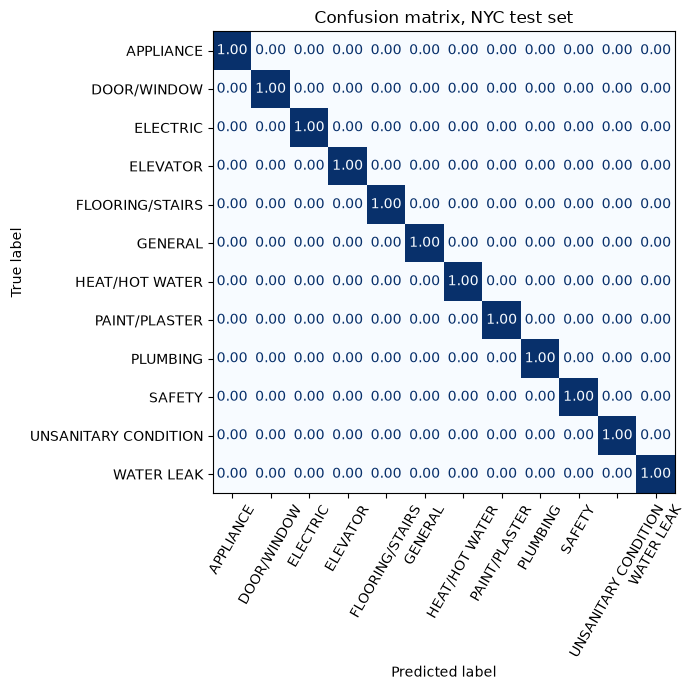

In [10]:
best = grid.best_estimator_
pred = best.predict(X_test)
print(f"NYC test set: accuracy {accuracy_score(y_test, pred):.4f}, macro-F1 {f1_score(y_test, pred, average='macro'):.4f} "
      f"(cross-validation was {grid.best_score_:.4f})\n")
print(classification_report(y_test, pred, digits=3))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=60, colorbar=False,
                                        normalize="true", values_format=".2f", cmap="Blues")
plt.title("Confusion matrix, NYC test set"); plt.tight_layout(); plt.show()

### Two results, and why they differ
The NYC test score is near perfect because NYC's text is a menu (Observations 2 and 3). The tenant sentences measure what the app really needs: handling new wording.

Tenant sentences: accuracy 0.438, macro-F1 0.364
(4 sentences per category, so each category's score is rough)

true
APPLIANCE               0.00
ELECTRIC                0.00
ELEVATOR                0.00
WATER LEAK              0.00
HEAT/HOT WATER          0.25
GENERAL                 0.25
SAFETY                  0.50
FLOORING/STAIRS         0.75
PLUMBING                0.75
UNSANITARY CONDITION    0.75
PAINT/PLASTER           1.00
DOOR/WINDOW             1.00 



,raw_text,true,predicted,confidence
1,"the shower only runs cold, there is no hot wat...",HEAT/HOT WATER,PLUMBING,0.46
2,radiators in the whole building are cold again,HEAT/HOT WATER,UNSANITARY CONDITION,0.27
3,hot water goes out every morning in our apartment,HEAT/HOT WATER,PLUMBING,0.39
4,kitchen tap has been dripping since Monday,PLUMBING,UNSANITARY CONDITION,0.33
8,water is leaking through my bedroom ceiling fr...,WATER LEAK,PLUMBING,0.46
9,there is a wet patch spreading on the living r...,WATER LEAK,PAINT/PLASTER,0.35
10,water keeps dripping from the ceiling whenever...,WATER LEAK,PAINT/PLASTER,0.34
11,a lot of water is coming down from the bathroo...,WATER LEAK,PAINT/PLASTER,0.34
15,rubbish is piling up outside the building and ...,UNSANITARY CONDITION,PLUMBING,0.28
24,the socket in the kitchen sparks when I plug a...,ELECTRIC,UNSANITARY CONDITION,0.28


,min_confidence,accepted,accuracy_on_accepted,sent_back_to_tenant
0,0.0,48/48,0.438,0
1,0.3,39/48,0.513,9
2,0.4,19/48,0.737,29
3,0.5,14/48,0.786,34


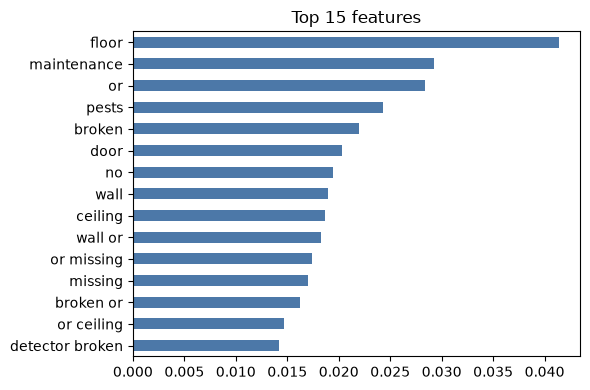

In [11]:
t_pred = best.predict(tenant_df["text"])
res_t = tenant_df.assign(predicted=t_pred, confidence=best.predict_proba(tenant_df["text"]).max(axis=1).round(2))
res_t["correct"] = res_t["true"] == res_t["predicted"]
print(f"Tenant sentences: accuracy {res_t['correct'].mean():.3f}, macro-F1 {f1_score(res_t['true'], t_pred, average='macro'):.3f}")
print("(4 sentences per category, so each category's score is rough)\n")
print(res_t.groupby("true")["correct"].mean().round(2).sort_values().to_string(), "\n")
display(res_t.loc[~res_t["correct"], ["raw_text", "true", "predicted", "confidence"]])

# Can the model tell when it is unsure? Accept only confident predictions; the rest go back to the tenant.
rows = [{"min_confidence": t, "accepted": f"{(res_t.confidence >= t).sum()}/48",
         "accuracy_on_accepted": round(res_t.loc[res_t.confidence >= t, "correct"].mean(), 3),
         "sent_back_to_tenant": int((res_t.confidence < t).sum())} for t in [0, 0.3, 0.4, 0.5]]
display(pd.DataFrame(rows))

# What does the forest rely on?
imp = pd.Series(best["rf"].feature_importances_, index=best["tfidf"].get_feature_names_out()).nlargest(15)
imp.sort_values().plot.barh(figsize=(6, 4), color="#4C78A8"); plt.title("Top 15 features"); plt.tight_layout(); plt.show()

**Reading this.** Fragments like *or*, *no* or *or missing* among the top features come from NYC's menu wording, so the model leans on NYC phrasing. Asking the tenant to confirm when the model is unsure raises accuracy on the accepted requests, but sends many requests back.

**Was unseen vocabulary the cause?** Our first guess was that the model fails on words it never saw. We test it by comparing the share of unseen words in right and wrong sentences, first counting all words, then ignoring filler words.

In [12]:
vocab, tok = set(best["tfidf"].get_feature_names_out()), best["tfidf"].build_analyzer()
def unseen(t, skip_filler):
    w = [x for x in tok(t) if " " not in x and not (skip_filler and x in ENGLISH_STOP_WORDS)]
    return sum(x not in vocab for x in w) / max(len(w), 1)
for name, flag in [("all words", False), ("content words only", True)]:
    res_t["u"] = tenant_df["text"].map(lambda t: unseen(t, flag)).values
    print(f"Share of unseen {name}:", res_t.groupby("correct")["u"].mean().round(2).rename({True: "right", False: "wrong"}).to_dict())

Share of unseen all words: {'wrong': 0.64, 'right': 0.61}
Share of unseen content words only: {'wrong': 0.62, 'right': 0.53}


If the shares are similar for right and wrong sentences, unseen words alone do not explain the mistakes, so we do **not** claim them as the cause. The errors may come from missing key words (like *radiators*, *cooker*) or from words like *ceiling* and *wall* that point to another category. We treat that as an idea to investigate next, not a result.

## Step 9: Compare with other models (Question 4)
One model's score cannot show whether it was a good choice. We train other models with **the same split, features and cross-validation** and compare them on both tests. Caveat: only the Random Forest was tuned by search; the others use sensible fixed settings, which slightly favours the forest.

Because 48 sentences is small, we also **resample them 5,000 times** to see how often each model beats the forest. That shows whether a gap is real or just luck.

,model,CV_F1,NYC_test_F1,tenant_acc,tenant_F1,seconds
0,Dummy (baseline),0.0426,0.0426,0.0833,0.0128,4.0
1,Naive Bayes,0.9998,0.9998,0.6042,0.5745,4.9
2,Logistic Regression,0.9998,0.9998,0.5417,0.4780,7.3
3,Linear SVM,0.9998,1.0000,0.6250,0.5723,219.4
4,Random Forest (base),0.9998,0.9996,0.4375,0.3639,14.3


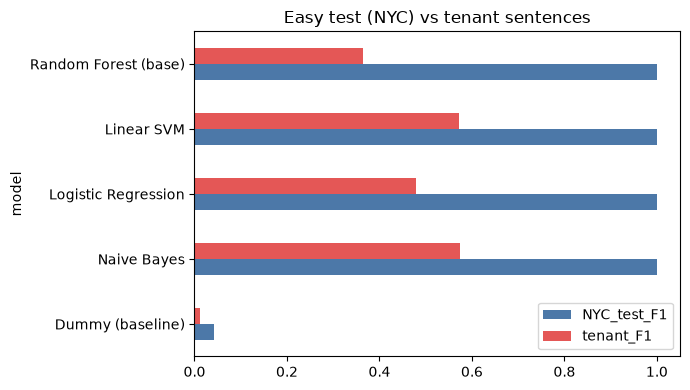

,model,accuracy,95% range,beat RF in
0,Naive Bayes,0.604,0.46 to 0.75,98% of resamples
1,Logistic Regression,0.542,0.40 to 0.69,94% of resamples
2,Linear SVM,0.625,0.48 to 0.77,100% of resamples
3,Random Forest (base),0.438,0.29 to 0.58,-


In [13]:
models = {"Dummy (baseline)": DummyClassifier(strategy="most_frequent"),
          "Naive Bayes": MultinomialNB(alpha=0.1),
          "Logistic Regression": LogisticRegression(C=10, max_iter=2000, class_weight="balanced", random_state=SEED),
          "Linear SVM": LinearSVC(C=1, class_weight="balanced", random_state=SEED),
          "Random Forest (base)": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED,
              max_depth=grid.best_params_["rf__max_depth"], min_samples_leaf=grid.best_params_["rf__min_samples_leaf"])}
truth = tenant_df["true"].to_numpy(); rows, hits = [], {}
for name, m in models.items():
    p = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)), ("m", m)])
    t0 = time.time(); cv = cross_validate(p, X_train, y_train, cv=cv5, scoring="f1_macro"); p.fit(X_train, y_train)
    tp = p.predict(tenant_df["text"]); hits[name] = (tp == truth).astype(int)
    rows.append({"model": name, "CV_F1": cv["test_score"].mean(), "NYC_test_F1": f1_score(y_test, p.predict(X_test), average="macro"),
                 "tenant_acc": hits[name].mean(), "tenant_F1": f1_score(truth, tp, average="macro"), "seconds": round(time.time() - t0, 1)})
cmp_df = pd.DataFrame(rows).round(4); display(cmp_df)
cmp_df.set_index("model")[["NYC_test_F1", "tenant_F1"]].plot.barh(figsize=(7, 4), color=["#4C78A8", "#E45756"])
plt.title("Easy test (NYC) vs tenant sentences"); plt.tight_layout(); plt.show()

idx = np.random.default_rng(SEED).integers(0, len(truth), size=(5000, len(truth)))
rf_acc = hits["Random Forest (base)"][idx].mean(axis=1); boot = []
for name, h in hits.items():
    if name.startswith("Dummy"): continue
    a = h[idx].mean(axis=1); lo, hi = np.percentile(a, [2.5, 97.5])
    boot.append({"model": name, "accuracy": round(h.mean(), 3), "95% range": f"{lo:.2f} to {hi:.2f}",
                 "beat RF in": "-" if "Forest" in name else f"{(a > rf_acc).mean():.0%} of resamples"})
pd.DataFrame(boot)

**Conclusion for Q4.** On NYC data every real model scores about 100%, so that test cannot separate them. On the tenant sentences the Random Forest scored lowest, and the resampling suggests the Linear SVM and Naive Bayes are very likely better on this test, while Logistic Regression is borderline. We have **not** established why. The tenant set is small and from one writer, so differences among the better models are not reliable. Random Forest remains our assigned base model; this check shows simpler models handled new wording better.

**Other validation we plan:**

| Method | What it checks |
|---|---|
| More tenant sentences from more writers, incl. Swahili/Sheng | Is the 48-sentence result reliable? |
| Train on Jan-Sep, test on Oct-Dec | Does it work on future requests? (Observation 4) |
| Train on NYC, test on Chicago 311 | Does it work in another city? |
| Trial with real tenants | Does it help in practice? |

## Step 10: Limitations and next steps
**Limitations**
1. **Menu-like text:** high NYC scores do not prove the model understands sentences.
2. **Small tenant test:** 48 sentences, one writing style, 4 per category.
3. **NYC is not Nairobi:** words, buildings and services differ; the mix even changed by borough and month.
4. **Elevator is rare:** 105 rows (21 in the test set), so its score is a weak estimate.
5. **Uneven comparison:** only the forest was tuned by search.
6. **Cause unknown:** we did not establish why the forest handles new wording worse.

**Next steps:** collect more tenant sentences (including Swahili and Sheng) and add some to training; map NYC categories to Nyumbani provider types; test on future months and Chicago data; try methods that understand word meaning; use the confidence score so the app asks the tenant when unsure.